In [83]:
import pandas as pd
import numpy as np
import sqlite3

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

from mlxtend.frequent_patterns import (
    apriori,
    association_rules
)

from prophet import Prophet

In [84]:
conn = sqlite3.connect("RetailIQ 360.db")

In [85]:
cursor= conn.cursor()

In [86]:
fact_order_items= pd.read_sql('''select * from fact_order_items''', conn)

# RFM ANALYSIS AND DID CUSTOMER SEGMENTATION BY ( RFM ) ANALYSIS.

In [8]:
rfm = pd.read_sql('''SELECT
    customer_id,
    MAX(order_date) AS last_order_date,
    COUNT(DISTINCT order_id) AS frequency,
    SUM(sales) AS monetary

FROM fact_order_items
GROUP BY customer_id''', conn)

In [9]:
rfm["last_order_date"] = pd.to_datetime(
    rfm["last_order_date"]
)

snapshot_date = (
    rfm["last_order_date"].max()
    + pd.Timedelta(days=1)
)

rfm["recency"] = (
    snapshot_date
    - rfm["last_order_date"]
).dt.days

In [10]:
rfm_features = rfm[
    ["recency", "frequency", "monetary"]
]

In [11]:
scaler = StandardScaler()

rfm_scaled = scaler.fit_transform(
    rfm_features
)

In [12]:
kmeans = KMeans(
    n_clusters=5,
    random_state=42
)

rfm["cluster"] = kmeans.fit_predict(
    rfm_scaled
)

In [13]:
rfm.to_sql(
    "customer_segments",
    conn,
    if_exists="replace",
    index=False
)

17994

# CHURN PREDICTION START FROM HERE!

In [14]:
rfm["churn"] = np.where(
    rfm["recency"] > 90,
    1,
    0
)

In [15]:
X = rfm[
    ["recency", "frequency", "monetary"]
]

y = rfm["churn"]

In [16]:
X_train, X_test, y_train, y_test = (
    train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=42
    )
)

In [17]:
model = LogisticRegression()

model.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

In [18]:
predictions = model.predict(X_test)

In [19]:
print(
    classification_report(
        y_test,
        predictions
    )
)

              precision    recall  f1-score   support

           0       1.00      1.00      1.00       875
           1       1.00      1.00      1.00      2724

    accuracy                           1.00      3599
   macro avg       1.00      1.00      1.00      3599
weighted avg       1.00      1.00      1.00      3599



In [20]:
rfm["churn_probability"] = (
    model.predict_proba(X)[:,1]
)

In [21]:
rfm.to_sql(
    "churn_predictions",
    conn,
    if_exists="replace",
    index=False
)

17994

In [87]:
sales_df_1 = pd.read_sql('''
SELECT
    DATE(order_date) AS order_date,
    SUM(sales) AS daily_sales

FROM 'fact_order_items_3_final'



GROUP BY DATE(order_date)
ORDER BY DATE(order_date)
''', conn)

In [88]:
sales_df_1['order_date'].max()

'2017-12-31'

In [89]:
sales_df_1.columns = ["ds", "y"]

sales_df_1["ds"] = pd.to_datetime(
    sales_df_1["ds"]
)

In [90]:
sales_df_1['y'] = sales_df_1['y'].clip(
    sales_df_1['y'].quantile(0.01),
    sales_df_1['y'].quantile(0.99)
)

In [91]:
sales_df_1

,ds,y
0,2015-01-01,32806.090690
1,2015-01-02,29818.210575
2,2015-01-03,36348.710648
3,2015-01-04,35738.970669
4,2015-01-05,31067.910603
...,...,...
1091,2017-12-27,31842.120759
1092,2017-12-28,31380.640748
1093,2017-12-29,31842.120759
1094,2017-12-30,19496.640504


C:\Users\User\anaconda3\Lib\site-packages\executing\executing.py:713: DeprecationWarning: ast.Str is deprecated and will be removed in Python 3.14; use ast.Constant instead
  right=ast.Str(s=sentinel),
C:\Users\User\anaconda3\Lib\ast.py:602: DeprecationWarning: Constant.__init__ got an unexpected keyword argument 's'. Support for arbitrary keyword arguments is deprecated and will be removed in Python 3.15.
  return Constant(*args, **kwargs)
C:\Users\User\anaconda3\Lib\ast.py:602: DeprecationWarning: Attribute s is deprecated and will be removed in Python 3.14; use value instead
  return Constant(*args, **kwargs)
C:\Users\User\anaconda3\Lib\ast.py:602: DeprecationWarning: Constant.__init__ missing 1 required positional argument: 'value'. This will become an error in Python 3.15.
  return Constant(*args, **kwargs)
C:\Users\User\anaconda3\Lib\site-packages\executing\executing.py:713: DeprecationWarning: ast.Str is deprecated and will be removed in Python 3.14; use ast.Constant instead
  r

Exception: Seasonality must be added prior to model fitting.

In [92]:
model = Prophet(
    yearly_seasonality=True,     # Force yearly seasonality
    weekly_seasonality=True,
    daily_seasonality=False,     # Usually not needed for sales
     seasonality_mode='multiplicative', # Try 'multiplicative' if sales are growing
    seasonality_prior_scale=10,  # Increase to give more weight to seasonality
    changepoint_prior_scale=0.15,# How flexible trend changes are (0.001 to 0.1)
    interval_width=0.95          # Confidence interval
)


In [93]:
model.add_seasonality(
    name='weekly',
    period=7,
    fourier_order=10
)

model.add_seasonality(
    name='monthly',
    period=30.5,
    fourier_order=5
)

In [94]:
model.fit(sales_df_1)

21:31:38 - cmdstanpy - INFO - Chain [1] start processing
21:31:38 - cmdstanpy - INFO - Chain [1] done processing


In [95]:
future = model.make_future_dataframe(
    periods=90
)

In [96]:
future

,ds
0,2015-01-01
1,2015-01-02
2,2015-01-03
3,2015-01-04
4,2015-01-05
...,...
1181,2018-03-27
1182,2018-03-28
1183,2018-03-29
1184,2018-03-30


In [97]:
forecast = model.predict(future)

In [98]:
future.tail()
forecast[['ds','yhat']].tail(100)

,ds,yhat
1086,2017-12-22,20590.015220
1087,2017-12-23,20715.993825
1088,2017-12-24,20548.816656
1089,2017-12-25,20542.699814
1090,2017-12-26,20528.520639
...,...,...
1181,2018-03-27,13820.285670
1182,2018-03-28,13553.067713
1183,2018-03-29,13814.624012
1184,2018-03-30,14065.912680


In [99]:
from prophet.diagnostics import cross_validation, performance_metrics

In [100]:
df_cv = cross_validation(
    model,
    initial='365 days',   # training size
    period='90 days',     # spacing between cutoffs
    horizon='90 days'     # prediction window
)

Seasonality has period of 365.25 days which is larger than initial window. Consider increasing initial.


  0%|          | 0/8 [00:00<?, ?it/s]

21:31:54 - cmdstanpy - INFO - Chain [1] start processing
21:31:54 - cmdstanpy - INFO - Chain [1] done processing
21:31:54 - cmdstanpy - INFO - Chain [1] start processing
21:31:54 - cmdstanpy - INFO - Chain [1] done processing
21:31:55 - cmdstanpy - INFO - Chain [1] start processing
21:31:55 - cmdstanpy - INFO - Chain [1] done processing
21:31:55 - cmdstanpy - INFO - Chain [1] start processing
21:31:56 - cmdstanpy - INFO - Chain [1] done processing
21:31:56 - cmdstanpy - INFO - Chain [1] start processing
21:31:56 - cmdstanpy - INFO - Chain [1] done processing
21:31:57 - cmdstanpy - INFO - Chain [1] start processing
21:31:57 - cmdstanpy - INFO - Chain [1] done processing
21:31:57 - cmdstanpy - INFO - Chain [1] start processing
21:31:57 - cmdstanpy - INFO - Chain [1] done processing
21:31:58 - cmdstanpy - INFO - Chain [1] start processing
21:31:58 - cmdstanpy - INFO - Chain [1] done processing


In [101]:
df_p = performance_metrics(df_cv)
df_p

,horizon,mse,rmse,mae,mape,mdape,smape,coverage
0,9 days,1.288017e+08,11349.084533,6080.678325,1.541323,0.080987,0.251605,0.777778
1,10 days,1.113809e+08,10553.714813,5620.185353,1.314447,0.080542,0.227607,0.805556
2,11 days,9.578907e+07,9787.189093,5297.993319,1.096642,0.086575,0.207072,0.819444
3,12 days,7.867713e+07,8870.013092,4742.852186,0.872931,0.084141,0.180786,0.847222
4,13 days,6.239033e+07,7898.754656,4359.412290,0.648969,0.087044,0.158078,0.875000
...,...,...,...,...,...,...,...,...
77,86 days,6.017911e+07,7757.519500,4578.342232,0.578609,0.085446,0.156863,0.888889
78,87 days,4.309836e+07,6564.934182,4128.485008,0.348634,0.081185,0.133016,0.902778
79,88 days,2.752283e+07,5246.220166,3834.230513,0.126075,0.085446,0.113934,0.888889
80,89 days,3.024081e+07,5499.164042,3866.821347,0.129009,0.081185,0.114809,0.875000


# from here we are gonna implement further code to make our this forecasting more meaning full:

In [117]:
# ============================================================
# STEP 0: FIX — Remove corrupted data (Oct 2017 onward)
# ============================================================
cutoff_date = '2017-10-01'
sales_df_1 = sales_df_1[sales_df_1['ds'] <= cutoff_date].copy()
print("Total rows after cutoff:", len(sales_df_1))
print(sales_df_1.tail())

Total rows after cutoff: 1005
             ds             y
1000 2017-09-27  32756.710434
1001 2017-09-28  39476.350411
1002 2017-09-29  42376.980556
1003 2017-09-30  44603.348776
1004 2017-10-01  44603.348776


In [119]:
# ============================================================
# STEP 0b: RE-TRAIN MODEL ON CLEAN DATA
# ============================================================
model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=True,
    daily_seasonality=False,
    seasonality_mode='multiplicative',
    seasonality_prior_scale=10,
    changepoint_prior_scale=0.15,
    interval_width=0.95
)
model.add_seasonality(name='weekly', period=7, fourier_order=10)
model.add_seasonality(name='monthly', period=30.5, fourier_order=5)
model.fit(sales_df_1)

future = model.make_future_dataframe(periods=90)
forecast = model.predict(future)
print(forecast[['ds','yhat']].tail(10))

18:43:37 - cmdstanpy - INFO - Chain [1] start processing
18:43:37 - cmdstanpy - INFO - Chain [1] done processing


             ds          yhat
1085 2017-12-21  38185.324138
1086 2017-12-22  38363.067867
1087 2017-12-23  38273.860283
1088 2017-12-24  37806.561013
1089 2017-12-25  37663.404106
1090 2017-12-26  37460.481557
1091 2017-12-27  36974.890913
1092 2017-12-28  37580.123812
1093 2017-12-29  38403.812556
1094 2017-12-30  38992.200317


In [120]:
# ============================================================
# STEP 0c: RE-RUN CROSS VALIDATION
# ============================================================
from prophet.diagnostics import cross_validation, performance_metrics

df_cv = cross_validation(
    model,
    initial='365 days',
    period='90 days',
    horizon='90 days'
)
df_p = performance_metrics(df_cv)
print(df_p)

Seasonality has period of 365.25 days which is larger than initial window. Consider increasing initial.


  0%|          | 0/7 [00:00<?, ?it/s]

18:43:44 - cmdstanpy - INFO - Chain [1] start processing
18:43:44 - cmdstanpy - INFO - Chain [1] done processing
18:43:45 - cmdstanpy - INFO - Chain [1] start processing
18:43:45 - cmdstanpy - INFO - Chain [1] done processing
18:43:46 - cmdstanpy - INFO - Chain [1] start processing
18:43:46 - cmdstanpy - INFO - Chain [1] done processing
18:43:46 - cmdstanpy - INFO - Chain [1] start processing
18:43:47 - cmdstanpy - INFO - Chain [1] done processing
18:43:47 - cmdstanpy - INFO - Chain [1] start processing
18:43:47 - cmdstanpy - INFO - Chain [1] done processing
18:43:48 - cmdstanpy - INFO - Chain [1] start processing
18:43:48 - cmdstanpy - INFO - Chain [1] done processing
18:43:48 - cmdstanpy - INFO - Chain [1] start processing
18:43:49 - cmdstanpy - INFO - Chain [1] done processing


   horizon           mse         rmse          mae      mape     mdape  \
0   9 days  1.296058e+07  3600.080367  2792.155961  0.083718  0.071936   
1  10 days  1.404636e+07  3747.846937  2889.848694  0.085907  0.071885   
2  11 days  1.323834e+07  3638.452354  2833.213421  0.083890  0.067575   
3  12 days  1.343793e+07  3665.778565  2914.278359  0.085223  0.071885   
4  13 days  1.220103e+07  3492.997504  2739.916530  0.081520  0.067359   
5  14 days  1.226167e+07  3501.667332  2769.795390  0.079835  0.071885   
6  15 days  1.041285e+07  3226.895077  2552.357706  0.073666  0.063538   
7  16 days  1.121935e+07  3349.530226  2691.091029  0.076371  0.071885   
8  17 days  1.113388e+07  3336.747322  2653.298469  0.076578  0.061581   
9  18 days  1.045739e+07  3233.788855  2589.100820  0.076044  0.059036   
10 19 days  1.056484e+07  3250.360667  2660.053997  0.077867  0.061581   
11 20 days  1.142931e+07  3380.726444  2776.699134  0.080715  0.066389   
12 21 days  1.191282e+07  3451.495284 

In [122]:
# ============================================================
# STEP 1: Forecast + Confidence Intervals (merged with actuals)
# ============================================================
forecast_export = forecast[['ds', 'yhat', 'yhat_lower', 'yhat_upper']].copy()
forecast_export.columns = ['date', 'forecast', 'forecast_lower', 'forecast_upper']

merged = pd.merge(
    sales_df_1.rename(columns={'ds': 'date', 'y': 'actual'}),
    forecast_export,
    on='date',
    how='outer'
).sort_values('date')

merged.to_csv('forecast_with_intervals.csv', index=False)
print(merged.tail(150))

           date        actual      forecast  forecast_lower  forecast_upper
945  2017-08-03  32615.600647  35254.165216    28043.815818    41833.400417
946  2017-08-04  38104.330609  35296.847211    28701.975171    41764.631734
947  2017-08-05  36351.330650  35330.047682    28558.997841    41113.338470
948  2017-08-06  31598.580628  35151.435794    28576.092444    41605.691706
949  2017-08-07  30545.870583  35296.049564    28957.042231    41580.878333
950  2017-08-08  35766.530709  35288.433232    28947.789835    41765.750440
951  2017-08-09  34648.910653  34861.240857    28403.828662    41411.858572
952  2017-08-10  39790.940736  35322.341233    29160.694772    41880.086758
953  2017-08-11  38809.880841  35877.645307    29578.837171    41820.659890
954  2017-08-12  32725.490654  36169.434507    29599.497277    42345.682290
955  2017-08-13  37437.890709  35916.581210    29634.438143    42913.987422
956  2017-08-14  37513.310715  35772.701033    29703.189773    42560.715371
957  2017-08

In [123]:
# ============================================================
# STEP 2: Back-test (Forecast vs Actual on last 90 days)
# ============================================================
holdout_days = 90
train = sales_df_1.iloc[:-holdout_days].copy()
test = sales_df_1.iloc[-holdout_days:].copy()

backtest_model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=True,
    daily_seasonality=False,
    seasonality_mode='multiplicative',
    seasonality_prior_scale=10,
    changepoint_prior_scale=0.15,
    interval_width=0.95
)
backtest_model.add_seasonality(name='weekly', period=7, fourier_order=10)
backtest_model.add_seasonality(name='monthly', period=30.5, fourier_order=5)
backtest_model.fit(train)

future_bt = backtest_model.make_future_dataframe(periods=holdout_days)
forecast_bt = backtest_model.predict(future_bt)

backtest_result = forecast_bt[['ds', 'yhat', 'yhat_lower', 'yhat_upper']].merge(
    test, on='ds', how='inner'
)
backtest_result.columns = ['date', 'forecast', 'forecast_lower', 'forecast_upper', 'actual']

backtest_result['abs_error'] = (backtest_result['actual'] - backtest_result['forecast']).abs()
backtest_result['ape'] = backtest_result['abs_error'] / backtest_result['actual'] * 100
backtest_result['error'] = backtest_result['actual'] - backtest_result['forecast']

backtest_result.to_csv('backtest_forecast_vs_actual.csv', index=False)
print(backtest_result.head())
print("Backtest MAPE:", backtest_result['ape'].mean())

18:44:29 - cmdstanpy - INFO - Chain [1] start processing
18:44:29 - cmdstanpy - INFO - Chain [1] done processing


        date      forecast  forecast_lower  forecast_upper        actual  \
0 2017-07-04  35846.494999    29556.805708    42383.962793  35844.940686   
1 2017-07-05  35189.487233    29148.905966    42384.801029  38244.650685   
2 2017-07-06  35443.894868    29172.256271    41586.761971  37948.560719   
3 2017-07-07  36017.454747    29510.542095    42358.894364  41165.110772   
4 2017-07-08  36263.446794    30237.812722    42618.344027  28744.470543   

     abs_error        ape        error  
0     1.554313   0.004336    -1.554313  
1  3055.163452   7.988473  3055.163452  
2  2504.665851   6.600160  2504.665851  
3  5147.656024  12.504900  5147.656024  
4  7518.976250  26.157992 -7518.976250  
Backtest MAPE: 7.940848323648846


                               ds      yearly
count                         275  275.000000
mean   2016-08-13 05:40:21.818181    0.007103
min           2015-01-01 00:00:00   -0.007467
25%           2015-12-08 12:00:00   -0.001701
50%           2016-11-15 00:00:00    0.002646
75%           2017-01-22 12:00:00    0.012973
max           2017-12-30 00:00:00    0.032992
std                           NaN    0.012470


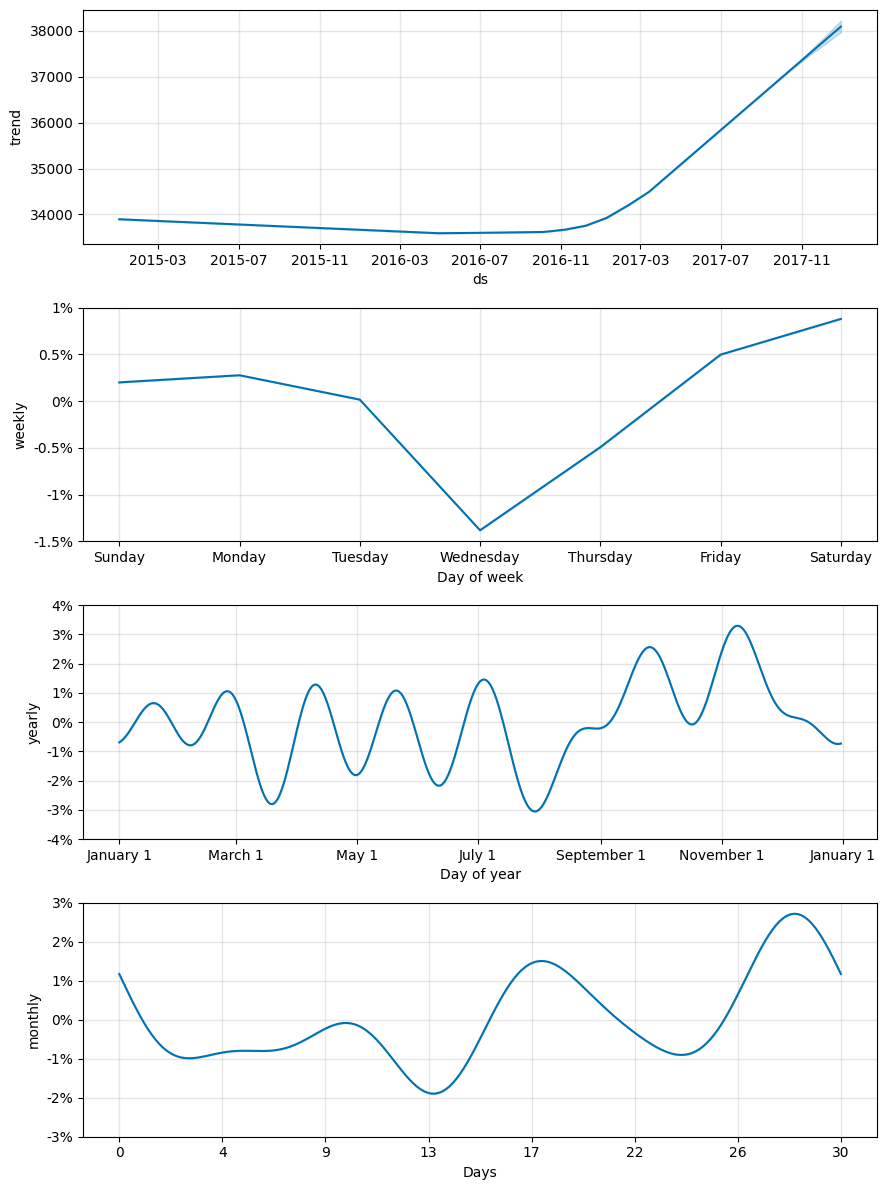

In [124]:
# ============================================================
# STEP 3: Seasonality Component Breakdown
# ============================================================
components = model.predict(future)
components_export = components[['ds', 'trend', 'yearly', 'weekly', 'monthly']].copy()
components_export.to_csv('forecast_components.csv', index=False)

dec_check = components_export[
    (components_export['ds'].dt.month.isin([11, 12, 1]))
][['ds', 'yearly']]
print(dec_check.describe())

fig = model.plot_components(forecast)

In [125]:
# ============================================================
# STEP 4: Rolling Accuracy Metrics
# ============================================================
df_p_export = df_p[['horizon', 'mape', 'mae', 'rmse', 'mse']].copy()
df_p_export['mape'] = df_p_export['mape'] * 100
df_p_export.to_csv('rolling_accuracy_metrics.csv', index=False)
print(df_p_export)

   horizon       mape          mae         rmse           mse
0   9 days   8.371835  2792.155961  3600.080367  1.296058e+07
1  10 days   8.590734  2889.848694  3747.846937  1.404636e+07
2  11 days   8.389037  2833.213421  3638.452354  1.323834e+07
3  12 days   8.522318  2914.278359  3665.778565  1.343793e+07
4  13 days   8.151954  2739.916530  3492.997504  1.220103e+07
5  14 days   7.983459  2769.795390  3501.667332  1.226167e+07
6  15 days   7.366617  2552.357706  3226.895077  1.041285e+07
7  16 days   7.637084  2691.091029  3349.530226  1.121935e+07
8  17 days   7.657758  2653.298469  3336.747322  1.113388e+07
9  18 days   7.604431  2589.100820  3233.788855  1.045739e+07
10 19 days   7.786732  2660.053997  3250.360667  1.056484e+07
11 20 days   8.071469  2776.699134  3380.726444  1.142931e+07
12 21 days   8.231863  2765.400768  3451.495284  1.191282e+07
13 22 days   8.141658  2742.698084  3430.190870  1.176621e+07
14 23 days   7.870063  2584.294431  3291.813768  1.083604e+07
15 24 da

In [126]:
# ============================================================
# STEP 5: Quarterly Actuals vs Forecast
# ============================================================
sales_df_1['year'] = sales_df_1['ds'].dt.year
sales_df_1['quarter'] = sales_df_1['ds'].dt.quarter

quarterly_actuals = sales_df_1.groupby(['year', 'quarter'])['y'].sum().reset_index()
quarterly_actuals.columns = ['year', 'quarter', 'total_sales']

forecast['year'] = forecast['ds'].dt.year
forecast['quarter'] = forecast['ds'].dt.quarter
forecast_quarterly = forecast[forecast['ds'] > sales_df_1['ds'].max()].groupby(
    ['year', 'quarter']
)['yhat'].sum().reset_index()
forecast_quarterly.columns = ['year', 'quarter', 'forecast_sales']

quarterly_actuals.to_csv('quarterly_actuals.csv', index=False)
forecast_quarterly.to_csv('quarterly_forecast.csv', index=False)

print(quarterly_actuals.tail())
print(forecast_quarterly)

    year  quarter   total_sales
7   2016        4  3.133129e+06
8   2017        1  3.070238e+06
9   2017        2  3.175893e+06
10  2017        3  3.353373e+06
11  2017        4  4.460335e+04
   year  quarter  forecast_sales
0  2017        4    3.410103e+06


In [127]:
# ============================================================
# STEP 6: Diagnose Lowest/Peak Forecast Days
# ============================================================
future_only = forecast[forecast['ds'] > sales_df_1['ds'].max()].copy()
lowest_day = future_only.loc[future_only['yhat'].idxmin()]
peak_day = future_only.loc[future_only['yhat'].idxmax()]

print("Lowest forecast day:", lowest_day['ds'], "value:", lowest_day['yhat'])
print("Peak forecast day:", peak_day['ds'], "value:", peak_day['yhat'])
print("\nWeekly seasonality on lowest day:", lowest_day['weekly'] if 'weekly' in lowest_day else 'N/A')
print("Yearly seasonality on lowest day:", lowest_day['yearly'] if 'yearly' in lowest_day else 'N/A')

Lowest forecast day: 2017-10-16 00:00:00 value: 36546.7540839048
Peak forecast day: 2017-10-31 00:00:00 value: 39207.60063229045

Weekly seasonality on lowest day: 0.0027719616847876327
Yearly seasonality on lowest day: -0.000683620929368061


In [128]:
# ============================================================
# STEP 5b: Add proper YoY growth metric
# ============================================================
q4_2016 = quarterly_actuals[(quarterly_actuals['year']==2016) & (quarterly_actuals['quarter']==4)]['total_sales'].values[0]
q4_2017_forecast = forecast_quarterly['forecast_sales'].values[0]

yoy_growth = (q4_2017_forecast - q4_2016) / q4_2016 * 100
print(f"Q4 2017 Forecast: {q4_2017_forecast:,.0f}")
print(f"Q4 2016 Actual: {q4_2016:,.0f}")
print(f"YoY Growth: {yoy_growth:.2f}%")

Q4 2017 Forecast: 3,410,103
Q4 2016 Actual: 3,133,129
YoY Growth: 8.84%


In [18]:
forecast.to_sql(
    "sales_forecast_without_18_final",
    conn,
    if_exists="replace",
    index=False
)

1186

# from here we try random forest regressor and try to forecast the 90 days next :

In [105]:
import pandas as pd
import numpy as np

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

# ==========================================
# STEP 1: Load Data
# ==========================================

sales_df = pd.read_sql("""
SELECT
    DATE(order_date) AS order_date,
    SUM(sales) AS daily_sales
FROM fact_order_items_3_final
GROUP BY DATE(order_date)
ORDER BY DATE(order_date)
""", conn)

sales_df.columns = ['ds', 'y']

sales_df['ds'] = pd.to_datetime(sales_df['ds'])

# ==========================================
# STEP 2: Create Features
# ==========================================

df = sales_df.copy()

# Calendar Features
df['day_of_week'] = df['ds'].dt.dayofweek
df['day_of_month'] = df['ds'].dt.day
df['month'] = df['ds'].dt.month
df['quarter'] = df['ds'].dt.quarter
df['week_of_year'] = df['ds'].dt.isocalendar().week.astype(int)

# Lag Features
df['lag_1'] = df['y'].shift(1)
df['lag_7'] = df['y'].shift(7)
df['lag_14'] = df['y'].shift(14)
df['lag_30'] = df['y'].shift(30)

# Rolling Features
df['rolling_mean_7'] = df['y'].shift(1).rolling(7).mean()
df['rolling_mean_30'] = df['y'].shift(1).rolling(30).mean()

df['rolling_std_7'] = df['y'].shift(1).rolling(7).std()
df['rolling_std_30'] = df['y'].shift(1).rolling(30).std()

# Remove nulls
df = df.dropna()

# ==========================================
# STEP 3: Train-Test Split
# Last 90 Days for Testing
# ==========================================

train = df.iloc[:-90]
test = df.iloc[-90:]

features = [
    'day_of_week',
    'day_of_month',
    'month',
    'quarter',
    'week_of_year',
    'lag_1',
    'lag_7',
    'lag_14',
    'lag_30',
    'rolling_mean_7',
    'rolling_mean_30',
    'rolling_std_7',
    'rolling_std_30'
]

X_train = train[features]
y_train = train['y']

X_test = test[features]
y_test = test['y']

# ==========================================
# STEP 4: Train Random Forest
# ==========================================

rf = RandomForestRegressor(
    n_estimators=500,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

# ==========================================
# STEP 5: Predict
# ==========================================

preds = rf.predict(X_test)

# ==========================================
# STEP 6: Metrics
# ==========================================

mae = mean_absolute_error(y_test, preds)

rmse = np.sqrt(
    mean_squared_error(y_test, preds)
)

mape = np.mean(
    np.abs((y_test - preds) / y_test)
) * 100

print("MAE :", round(mae,2))
print("RMSE:", round(rmse,2))
print("MAPE:", round(mape,2), "%")


MAE : 21191.02
RMSE: 26349.25
MAPE: 557.24 %


In [ ]:
dim_product= pd.read_sql('''select * from dim_product''',conn)

# MARKET BASKET ANALYSIS

In [23]:
basket = pd.read_sql(
    '''  SELECT
        foi.order_id,
        dp.product_name

    FROM fact_order_items AS foi

    LEFT JOIN dim_product AS dp
        ON foi.product_id = dp.product_id''',
    conn
)

In [24]:
basket_matrix = (
    basket
    .groupby(
        ["order_id", "product_name"]
    )["product_name"]
    .count()
    .unstack()
    .fillna(0)
)

In [25]:
type(basket_matrix)

pandas.DataFrame

In [26]:
basket_matrix = (basket_matrix > 0).astype(int)

In [27]:
frequent_items = apriori(
    basket_matrix,
    min_support=0.01,
    use_colnames=True
)

C:\Users\User\anaconda3\Lib\site-packages\mlxtend\frequent_patterns\fpcommon.py:175: DeprecationWarning: DataFrames with non-bool types result in worse computationalperformance and their support might be discontinued in the future.Please use a DataFrame with bool type
  warnings.warn(


In [28]:
rules = association_rules(
    frequent_items,
    metric="lift",
    min_threshold=1
)

In [29]:
rules['antecedents'] = rules['antecedents'].apply(
    lambda x: ', '.join(list(x))
)

rules['consequents'] = rules['consequents'].apply(
    lambda x: ', '.join(list(x))
)

In [30]:
rules.to_sql(
    "market_basket_rules",
    conn,
    if_exists="replace",
    index=False
)

6